In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download('sootersaalu/amazon-top-50-bestselling-books-2009-2019')
df = pd.read_csv(os.path.join(path, 'bestsellers with categories.csv'))

In [3]:
df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [4]:
df.shape
# Відповідь: Про скільки книг зберігає дані датасет? 550

(550, 7)

In [5]:
df.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']

In [6]:
df.isna().sum()
# Відповідь: Чи є в якихось змінних пропуски? Ні

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64

In [7]:
df['genre'].unique()
# Відповідь: Які є унікальні жанри? Non Fiction, Fiction

<StringArray>
['Non Fiction', 'Fiction']
Length: 2, dtype: str

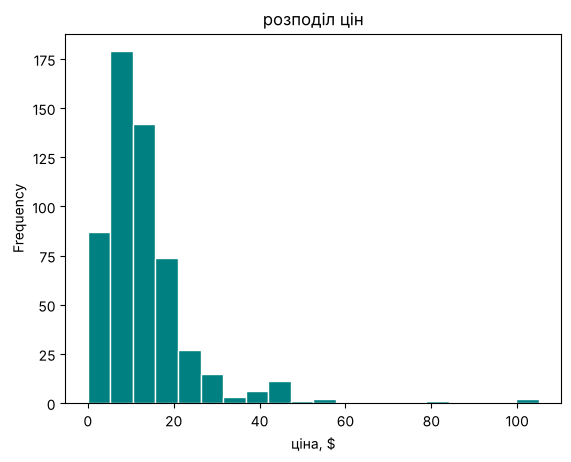

In [8]:
df['price'].plot(kind='hist', bins=20, color='teal', edgecolor='white')
plt.title('розподіл цін')
plt.xlabel('ціна, $')
plt.show()

In [9]:
df['price'].max()
# Відповідь: Максимальна ціна? 105

np.int64(105)

In [10]:
df['price'].min()
# Відповідь: Мінімальна ціна? 0

np.int64(0)

In [11]:
df['price'].mean()
# Відповідь: Середня ціна? 13.1

np.float64(13.1)

In [12]:
df['price'].median()
# Відповідь: Медіанна ціна? 11.0

np.float64(11.0)

In [13]:
df['user_rating'].max()
# Відповідь: Який рейтинг у датасеті найвищий? 4.9

np.float64(4.9)

In [14]:
df[df['user_rating'] == df['user_rating'].max()].shape[0]
# Відповідь: Скільки книг мають такий рейтинг? 52

52

In [15]:
df.loc[df['reviews'].idxmax(), 'name']
# Відповідь: Яка книга має найбільше відгуків? Where the Crawdads Sing

'Where the Crawdads Sing'

In [16]:
df2015 = df[df['year'] == 2015]
df2015.loc[df2015['price'].idxmax(), 'name']
# Відповідь: З тих книг, що потрапили до Топ-50 у 2015 році, яка книга найдорожча? Publication Manual of the American Psychological Association, 6th Edition

'Publication Manual of the American Psychological Association, 6th Edition'

In [17]:
df[(df['year'] == 2010) & (df['genre'] == 'Fiction')].shape[0]
# Відповідь: Скільки книг жанру Fiction потрапили до Топ-50 у 2010 році? 20

20

In [18]:
df[(df['year'].isin([2010, 2011])) & (df['user_rating'] == 4.9)].shape[0]
# Відповідь: Скільки книг з рейтингом 4.9 потрапило до рейтингу у 2010 та 2011 роках? 1

1

In [19]:
df2015[df2015['price'] < 8].sort_values(by='price')
# Відповідь: Яка книга остання у відсортованому списку? Old School (Diary of a Wimpy Kid #10)

,name,author,user_rating,reviews,price,year,genre
507,To Kill a Mockingbird,Harper Lee,4.8,26234,0,2015,Fiction
54,Creative Haven Creative Cats Coloring Book (Ad...,Marjorie Sarnat,4.8,4022,4,2015,Non Fiction
206,Knock-Knock Jokes for Kids,Rob Elliott,4.5,3673,4,2015,Non Fiction
111,First 100 Words,Roger Priddy,4.7,17323,4,2015,Non Fiction
210,Laugh-Out-Loud Jokes for Kids,Rob Elliott,4.6,6990,4,2015,Non Fiction
123,Giraffes Can't Dance,Giles Andreae,4.8,14038,4,2015,Fiction
55,Creative Haven Owls Coloring Book (Adult Color...,Marjorie Sarnat,4.8,3871,5,2015,Non Fiction
63,Dear Zoo: A Lift-the-Flap Book,Rod Campbell,4.8,10922,5,2015,Fiction
224,Love You Forever,Robert Munsch,4.8,18613,5,2015,Fiction
478,The Very Hungry Caterpillar,Eric Carle,4.9,19546,5,2015,Fiction


In [20]:
df_genre_price = df.groupby('genre')['price'].agg(['min', 'max'])
df_genre_price
# Відповідь: Максимальна ціна для жанру Fiction: 82
# Відповідь: Мінімальна ціна для жанру Fiction: 0
# Відповідь: Максимальна ціна для жанру Non Fiction: 105
# Відповідь: Мінімальна ціна для жанру Non Fiction: 0

,min,max
genre,,
Fiction,0,82
Non Fiction,0,105


In [21]:
df_author_by_books = df.groupby('author')[['name']].agg('count')
df_author_by_books.columns = ['count']
df_author_by_books.shape
# Відповідь: Якої розмірності вийшла таблиця? 248 x 1

(248, 1)

In [22]:
df_author_by_books['count'].idxmax()
# Відповідь: Який автор має найбільше книг? Jeff Kinney

'Jeff Kinney'

In [23]:
df_author_by_books['count'].max()
# Відповідь: Скільки книг цього автора? 12

np.int64(12)

In [24]:
df_by_mean = df.groupby('author')[['user_rating']].agg('mean')
df_by_mean['user_rating'].idxmin()
# Відповідь: У якого автора середній рейтинг мінімальний? Donna Tartt

'Donna Tartt'

In [25]:
df_by_mean['user_rating'].min()
# Відповідь: Який у цього автора середній рейтинг? 3.9

np.float64(3.9)

In [26]:
df_concat = pd.concat([df_author_by_books, df_by_mean], axis=1)
df_concat = df_concat.sort_values(by=['count', 'user_rating'])
df_concat.head(1)
# Відповідь: Який автор перший у списку? Muriel Barbery

,count,user_rating
author,,
Muriel Barbery,1,4.0


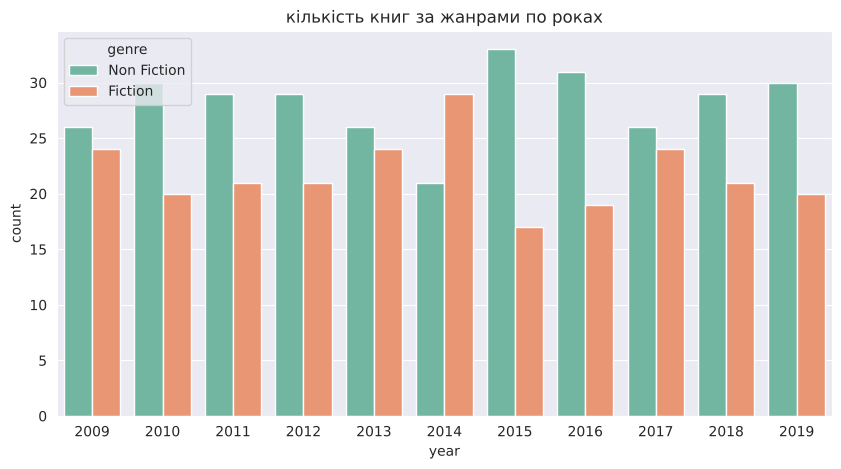

In [27]:
sns.set_style('darkgrid')
plt.figure(figsize=(10, 5))
sns.countplot(x='year', hue='genre', data=df, palette='Set2')
plt.title('кількість книг за жанрами по роках')
plt.show()

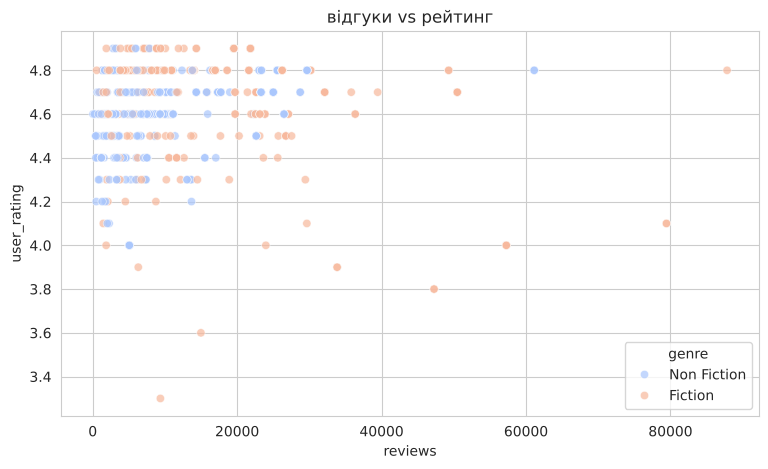

In [28]:
sns.set_style('whitegrid')
plt.figure(figsize=(9, 5))
sns.scatterplot(x='reviews', y='user_rating', hue='genre', data=df, palette='coolwarm', alpha=0.7)
plt.title('відгуки vs рейтинг')
plt.show()

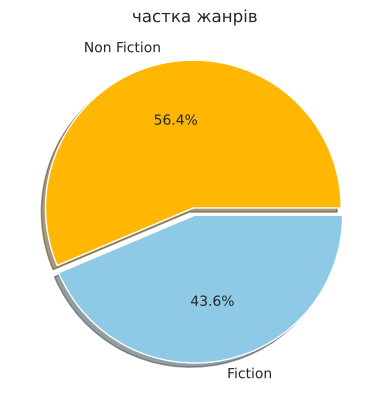

In [29]:
counts = df['genre'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%.1f%%', colors=['#FFB703', '#8ECAE6'], explode=[0.05, 0], shadow=True)
plt.title('частка жанрів')
plt.show()